# Task 2 - 01 Exploratory Data Analysis (EDA)

**Project:** Visual inspection assistant for an organic farm / produce warehouse - classify **fresh vs rotten** apples, bananas and oranges (6 classes).

## Objective
Before building any model we must *understand the data*: how many images per class, are the classes balanced, are all files readable, what sizes/colours do the images have? Problems found here are fixed in notebook 02.

## Short theory
* **Class imbalance** - if one class is much bigger, a model can reach high accuracy by favouring it. We measure the *imbalance ratio* = largest class / smallest class.
* **Image statistics** - a CNN needs a fixed input size, so we check width/height/aspect ratio to decide how to resize.
* **Colour in HSV space** - HSV separates *hue* (colour type), *saturation* (colour intensity) and *value* (brightness). Rotten fruit is usually darker and less saturated (brown spots), so these simple statistics already differ between fresh and rotten - this is the signal a CNN can learn.

In [1]:
# --- Setup: find the project root (the folder that contains "src") so imports work ---
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from src.task2 import config

warnings.filterwarnings("ignore", category=FutureWarning)
config.ensure_out_dir()
print("Project root :", ROOT.name)
print("Data folder  :", config.DATA_DIR)
print("Output folder:", config.OUT_DIR)

from src.task2 import data_utils, viz

Project root : FCVG101_Coursework
Data folder  : C:\Users\admin\Desktop\FundementalOfComputerVision\FCVG101_Coursework\Task2\data\raw
Output folder: C:\Users\admin\Desktop\FundementalOfComputerVision\FCVG101_Coursework\Task2\outputs


## Step 1 - Data ingestion
**What:** `discover_dataset` walks through the data folder, finds every folder that contains images (= one class) and builds a table with one row per image.
**Why:** one table (DataFrame) is the single source of truth for all later steps. Class names such as `freshapples` are parsed into *freshness* + *fruit*.

In [2]:
df = data_utils.discover_dataset(config.DATA_DIR)
class_names = data_utils.class_names_from_df(df)
print("Total images:", len(df))
print("Classes     :", class_names)
print("Source split:", df["source_split"].value_counts().to_dict())
df.head()

Total images: 1200
Classes     : ['fresh_apple', 'fresh_banana', 'fresh_orange', 'rotten_apple', 'rotten_banana', 'rotten_orange']
Source split: {'none': 1200}


,path,label,class_name,fruit,freshness,source_split
0,C:\Users\admin\Desktop\FundementalOfComputerVi...,0,fresh_apple,apple,fresh,none
1,C:\Users\admin\Desktop\FundementalOfComputerVi...,0,fresh_apple,apple,fresh,none
2,C:\Users\admin\Desktop\FundementalOfComputerVi...,0,fresh_apple,apple,fresh,none
3,C:\Users\admin\Desktop\FundementalOfComputerVi...,0,fresh_apple,apple,fresh,none
4,C:\Users\admin\Desktop\FundementalOfComputerVi...,0,fresh_apple,apple,fresh,none


## Step 2 - Class balance
**What:** count the images per class and compute the imbalance ratio.
**Why:** a strong imbalance would need countermeasures (class-weighted loss, see notebook 03); missing classes would be a data problem.

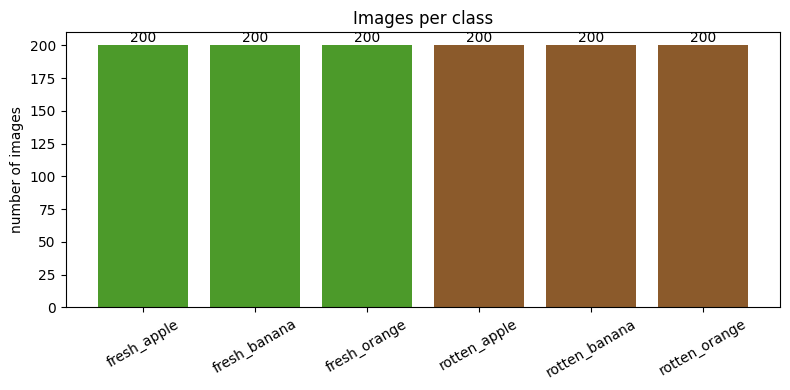

Imbalance ratio (largest / smallest class): 1.00


freshness,fresh,rotten,All
fruit,,,
apple,200,200,400
banana,200,200,400
orange,200,200,400
All,600,600,1200


In [3]:
viz.plot_class_counts(df, save_path=config.OUT_DIR / "eda_class_counts.png")
plt.show()

imbalance = data_utils.imbalance_ratio(df)
print(f"Imbalance ratio (largest / smallest class): {imbalance:.2f}")
pd.crosstab(df["fruit"], df["freshness"], margins=True)

## Step 3 - Read every image: sizes, format, colour mode, corruption
**What:** `analyse_images` opens each file with PIL, verifies it, and records width, height (read from the file header and corrected for EXIF rotation, so huge phone photos are not fully decoded), colour mode, file size, brightness, HSV colour statistics (on a tiny thumbnail), a perceptual hash and an MD5 hash.
**Why:** a corrupt or tiny file would crash training or add noise. This is the *data quality check*.

In [4]:
stats = data_utils.analyse_images(df)
stats["aspect_ratio"] = stats["width"] / stats["height"].clip(lower=1)
stats["format"] = stats["path"].map(lambda p: Path(p).suffix.lower())
stats["megapixels"] = stats["width"] * stats["height"] / 1e6

print("Status      :", stats["status"].value_counts().to_dict())
print("File formats:", stats["format"].value_counts().to_dict())
print("Colour modes:", stats["mode"].value_counts().to_dict())
print("Photos with an EXIF rotation flag (width/height are swapped for them):", int(stats["exif_rotated"].sum()))
print(f"Total size of the raw images: {stats['file_kb'].sum() / 1024 / 1024:.2f} GB")
stats[["width", "height", "megapixels", "aspect_ratio", "file_kb", "brightness"]].describe().round(2)

Status      : {'ok': 1200}
File formats: {'.jpg': 1200}
Colour modes: {'RGB': 1200}
Photos with an EXIF rotation flag (width/height are swapped for them): 0
Total size of the raw images: 1.13 GB


,width,height,megapixels,aspect_ratio,file_kb,brightness
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,2599.49,2353.89,6.64,1.13,986.83,165.02
std,867.97,771.42,3.50,0.27,852.19,18.99
min,469.00,446.00,0.21,0.57,34.90,75.60
25%,2171.50,1955.75,4.43,0.96,583.78,155.48
50%,2720.00,2433.50,6.56,1.07,803.05,167.98
75%,3120.00,2893.25,9.06,1.33,1094.47,177.35
max,4160.00,4160.00,12.98,2.52,4551.00,209.05


## Step 4 - Image size and aspect-ratio distribution
**What:** histograms of width, height, aspect ratio and file size.
**Why:** if all images were the same size, a plain resize would be enough; very different aspect ratios mean a plain resize would stretch the fruit, so we resize the short side and centre-crop.

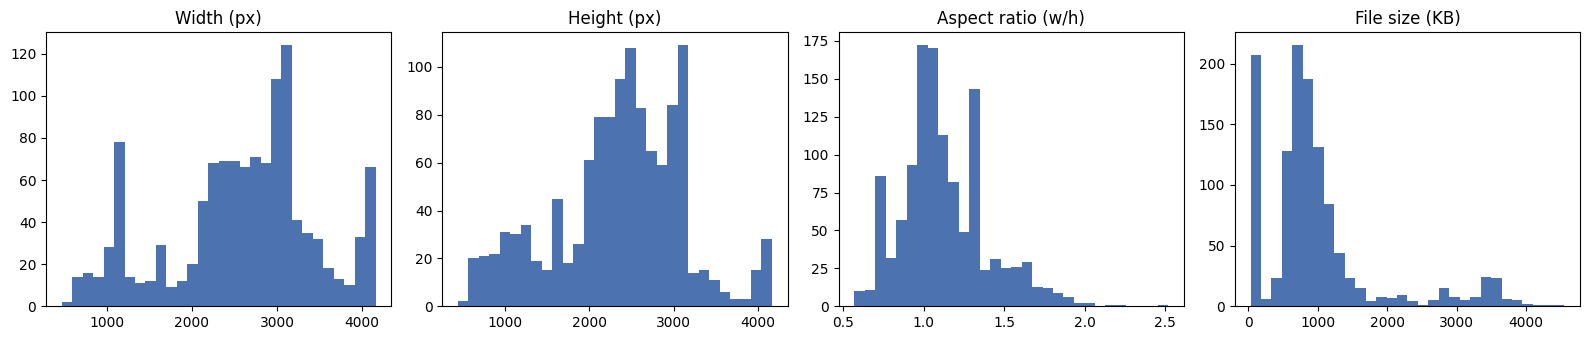

Number of distinct (width, height) pairs: 1023


In [5]:
good = stats[stats["status"] == "ok"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, column, title in zip(axes, ["width", "height", "aspect_ratio", "file_kb"],
                             ["Width (px)", "Height (px)", "Aspect ratio (w/h)", "File size (KB)"]):
    ax.hist(good[column], bins=30, color="#4c72b0")
    ax.set_title(title)
fig.tight_layout()
fig.savefig(config.OUT_DIR / "eda_image_sizes.png", dpi=130, bbox_inches="tight")
plt.show()
print("Number of distinct (width, height) pairs:", good.groupby(["width", "height"]).ngroups)

## Step 5 - Corrupt and very small images
**What:** list files that cannot be opened and files smaller than the minimum size (`config.MIN_IMAGE_SIZE`).
**Why:** these are removed in notebook 02 (cleaning).

In [6]:
corrupt = stats[stats["status"] == "corrupt"]
small = good[(good["width"] < config.MIN_IMAGE_SIZE) | (good["height"] < config.MIN_IMAGE_SIZE)]
print("Corrupt images:", len(corrupt))
print("Too small (<%d px):" % config.MIN_IMAGE_SIZE, len(small))
pd.concat([corrupt, small])[["path", "width", "height", "status"]].head(10)

Corrupt images: 0
Too small (<32 px): 0


,path,width,height,status


## Step 6 - Duplicate check
**What:** images with the same MD5 hash are byte-identical copies.
**Why:** duplicates in both train and test sets would *leak* information and inflate the test accuracy.

In [7]:
dup_mask = stats.duplicated(subset="md5", keep=False) & (stats["status"] == "ok")
dups = stats[dup_mask].sort_values("md5")
n_extra_copies = int(stats[stats["status"] == "ok"].duplicated(subset="md5").sum())
print("Images that belong to a duplicate group:", len(dups))
print("Extra copies that would be removed     :", n_extra_copies)
dups[["path", "class_name", "md5"]].head(10)

Images that belong to a duplicate group: 14
Extra copies that would be removed     : 7


,path,class_name,md5
475,C:\Users\admin\Desktop\FundementalOfComputerVi...,fresh_orange,0997a7ad7e4a6303ba560944c7774406
559,C:\Users\admin\Desktop\FundementalOfComputerVi...,fresh_orange,0997a7ad7e4a6303ba560944c7774406
573,C:\Users\admin\Desktop\FundementalOfComputerVi...,fresh_orange,0bbaa7e6891938911c69f9480af13143
587,C:\Users\admin\Desktop\FundementalOfComputerVi...,fresh_orange,0bbaa7e6891938911c69f9480af13143
562,C:\Users\admin\Desktop\FundementalOfComputerVi...,fresh_orange,10a4651896ca2bcc5b6075ec603dda03
576,C:\Users\admin\Desktop\FundementalOfComputerVi...,fresh_orange,10a4651896ca2bcc5b6075ec603dda03
520,C:\Users\admin\Desktop\FundementalOfComputerVi...,fresh_orange,c3ba6f74967a8253af0d6b2ee1c80d4f
575,C:\Users\admin\Desktop\FundementalOfComputerVi...,fresh_orange,c3ba6f74967a8253af0d6b2ee1c80d4f
563,C:\Users\admin\Desktop\FundementalOfComputerVi...,fresh_orange,c6089862f60a1d6b52611b31ac1185cc
577,C:\Users\admin\Desktop\FundementalOfComputerVi...,fresh_orange,c6089862f60a1d6b52611b31ac1185cc


## Step 7 - Brightness and colour statistics (fresh vs rotten)
**What:** mean hue, saturation and value (brightness) of every image, compared between fresh and rotten for each fruit.
**Why:** if simple colour statistics already separate the classes, a CNN will find this (and much more: spots, texture, shape) easily. Hue is shown in degrees (0 = red, 60 = yellow, 120 = green); it is a circular value, averaged per image with saturation weights so that the grey/white background hardly counts.

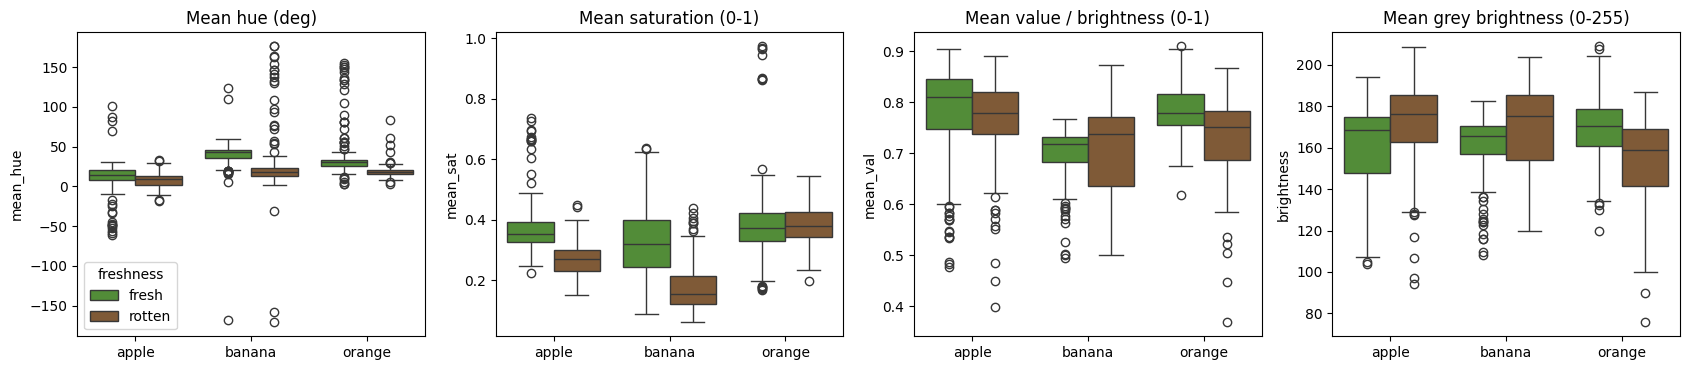

mean_hue  mean_sat  mean_val  brightness
fruit  freshness                                          
apple  fresh        12.299     0.374     0.782     161.271
       rotten        8.411     0.269     0.765     172.095
banana fresh        39.318     0.332     0.702     161.773
       rotten       25.348     0.175     0.712     170.780
orange fresh        37.482     0.389     0.787     169.114
       rotten       18.897     0.382     0.734     155.102

In [8]:
import seaborn as sns

palette = {"fresh": viz.FRESH_COLOR, "rotten": viz.ROTTEN_COLOR}
plot_df = good.assign(mean_hue=((good["mean_hue"] + 180) % 360) - 180)   # shift so that red (0 deg) is in the middle, not split at 0/360
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, column, title in zip(axes, ["mean_hue", "mean_sat", "mean_val", "brightness"],
                             ["Mean hue (deg)", "Mean saturation (0-1)", "Mean value / brightness (0-1)",
                              "Mean grey brightness (0-255)"]):
    sns.boxplot(data=plot_df, x="fruit", y=column, hue="freshness", palette=palette, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    if column != "mean_hue":
        ax.get_legend().remove()                                   # one legend is enough
fig.tight_layout()
fig.savefig(config.OUT_DIR / "eda_color_stats.png", dpi=130, bbox_inches="tight")
plt.show()

color_table = plot_df.groupby(["fruit", "freshness"])[["mean_hue", "mean_sat", "mean_val", "brightness"]].mean().round(3)
color_table

## Step 8 - Sample images per class
**What:** 4 random images from each class.
**Why:** a human look catches things statistics miss (watermarks, odd backgrounds, wrong labels). `load_thumbnail` decodes huge photos at reduced size, so this is fast.

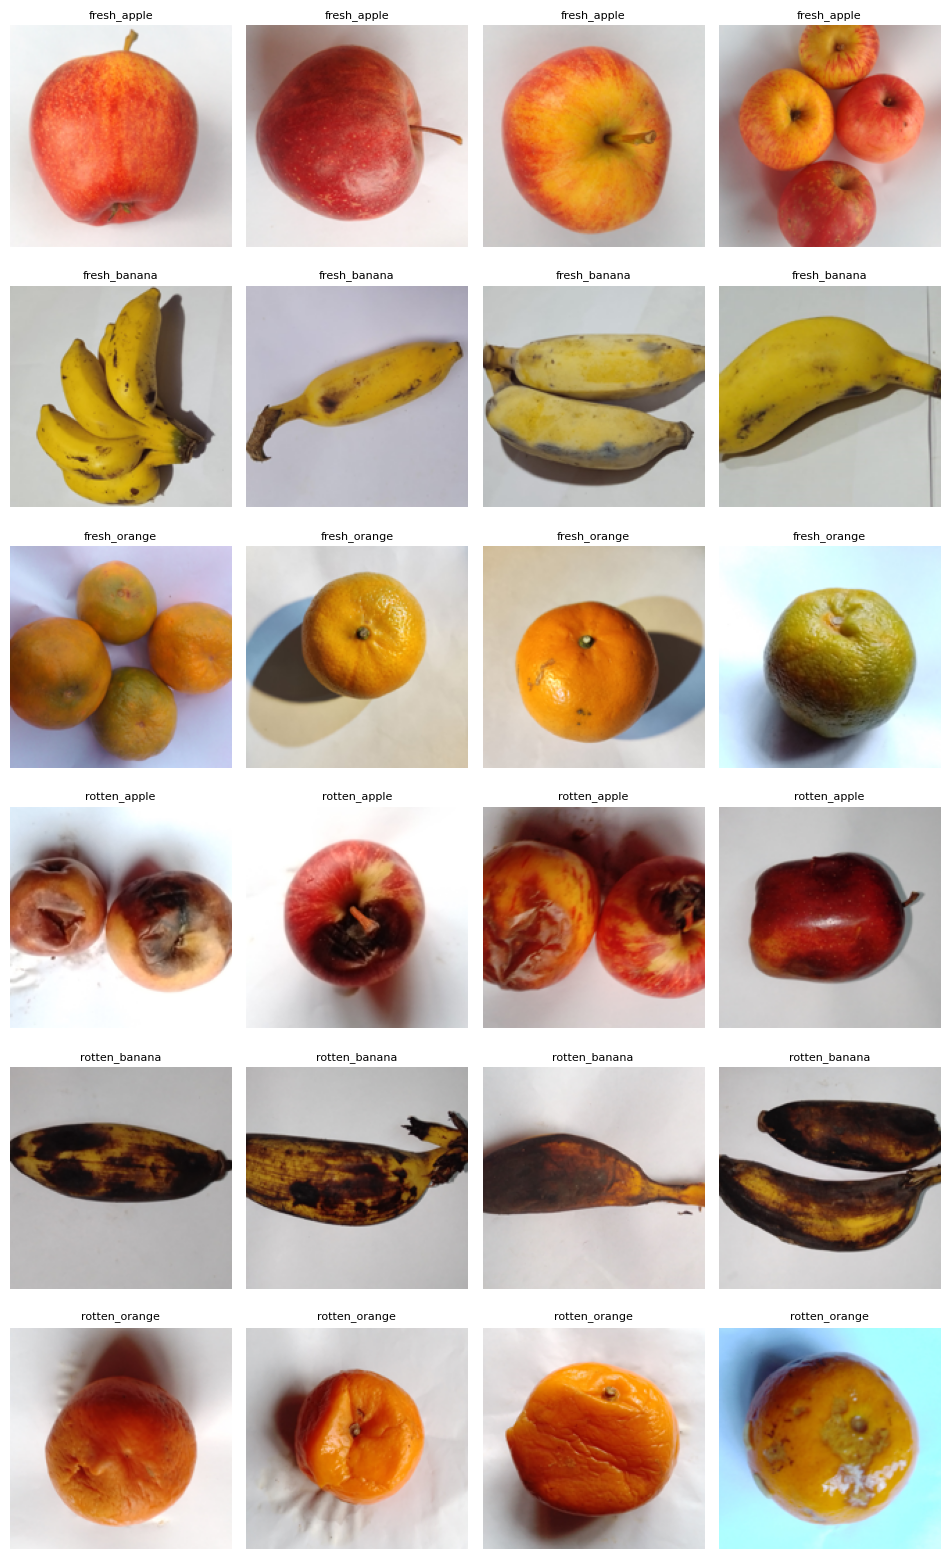

In [9]:
samples = (good.groupby("class_name", group_keys=False)
               .apply(lambda g: g.sample(min(4, len(g)), random_state=config.SEED)))
images = [data_utils.load_thumbnail(p, 160) for p in samples["path"]]
titles = [name for name in samples["class_name"]]
viz.show_image_grid(images, titles, ncols=4, save_path=config.OUT_DIR / "eda_samples.png")
plt.show()

## Step 9 - Save the EDA summary
All numbers are stored in `eda_summary.json` so they can be quoted in the report.

In [10]:
summary = {
    "n_images": int(len(df)),
    "class_names": class_names,
    "class_counts": df["class_name"].value_counts().sort_index().to_dict(),
    "source_split_counts": df["source_split"].value_counts().to_dict(),
    "imbalance_ratio": round(imbalance, 3),
    "n_corrupt": int(len(corrupt)),
    "n_too_small": int(len(small)),
    "n_extra_duplicate_copies": n_extra_copies,
    "n_exif_rotated": int(stats["exif_rotated"].sum()),
    "raw_size_gb": round(float(stats["file_kb"].sum() / 1024 / 1024), 3),
    "megapixels_min_median_max": [round(float(good["megapixels"].min()), 2), round(float(good["megapixels"].median()), 2), round(float(good["megapixels"].max()), 2)],
    "aspect_ratio_min_median_max": [round(float(good["aspect_ratio"].min()), 2), round(float(good["aspect_ratio"].median()), 2), round(float(good["aspect_ratio"].max()), 2)],
    "colour_modes": good["mode"].value_counts().to_dict(),
    "file_formats": stats["format"].value_counts().to_dict(),
    "width_min_median_max": [int(good["width"].min()), int(good["width"].median()), int(good["width"].max())],
    "height_min_median_max": [int(good["height"].min()), int(good["height"].median()), int(good["height"].max())],
    "mean_by_freshness": plot_df.groupby("freshness")[["mean_hue", "mean_sat", "mean_val", "brightness"]].mean().round(3).to_dict("index"),
}
(config.OUT_DIR / "eda_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2)[:1200])

{
  "n_images": 1200,
  "class_names": [
    "fresh_apple",
    "fresh_banana",
    "fresh_orange",
    "rotten_apple",
    "rotten_banana",
    "rotten_orange"
  ],
  "class_counts": {
    "fresh_apple": 200,
    "fresh_banana": 200,
    "fresh_orange": 200,
    "rotten_apple": 200,
    "rotten_banana": 200,
    "rotten_orange": 200
  },
  "source_split_counts": {
    "none": 1200
  },
  "imbalance_ratio": 1.0,
  "n_corrupt": 0,
  "n_too_small": 0,
  "n_extra_duplicate_copies": 7,
  "n_exif_rotated": 0,
  "raw_size_gb": 1.129,
  "megapixels_min_median_max": [
    0.21,
    6.56,
    12.98
  ],
  "aspect_ratio_min_median_max": [
    0.57,
    1.07,
    2.52
  ],
  "colour_modes": {
    "RGB": 1200
  },
  "file_formats": {
    ".jpg": 1200
  },
  "width_min_median_max": [
    469,
    2720,
    4160
  ],
  "height_min_median_max": [
    446,
    2433,
    4160
  ],
  "mean_by_freshness": {
    "fresh": {
      "mean_hue": 29.7,
      "mean_sat": 0.365,
      "mean_val": 0.757,
      "br

## Summary / Observations
* **Dataset size:** 1,200 images, 6 classes (fresh / rotten x apple, banana, orange), exactly 200 per class; no ready-made train/test split (`source_split = none`). Imbalance ratio **1.00** (perfectly balanced), so no resampling is needed.
* **Image sizes:** large phone photos, 1.13 GB in total. Width 469-4160 px (median 2720), height 446-4160 px (median 2433), median 6.6 megapixels (max 13 MP); 1,023 different (width, height) pairs; aspect ratio 0.57-2.52 (median 1.07). All JPEG, all RGB, none with an EXIF rotation flag. => images must be shrunk (cached at a 256 px short side) and centre-cropped to 224 x 224 instead of being stretched.
* **Data quality:** 0 corrupt files, 0 images below 32 px, 0 grayscale images. **7 exact duplicate copies** (byte-identical files, all in `fresh_orange`) -> removed in notebook 02.
* **Colour statistics (HSV, per-image means):** rotten fruit is clearly **less saturated** for apple (0.27 vs 0.37) and especially banana (0.18 vs 0.33), and its hue shifts from yellow (about 39 deg) towards orange-brown (about 25 deg) for banana. For **orange** the simple statistics barely differ (saturation 0.38 vs 0.39, hue 19 vs 37 deg, brightness not consistent). Brightness alone is not a reliable signal for any fruit (the box plots overlap strongly).
* **What this means:** colour/saturation already separates most fresh/rotten pairs, but not for oranges, where rot appears as local dark patches and wrinkled skin; a CNN can use texture and spots, so it should do better than colour statistics. We expect orange to be the hardest class. Hue is therefore only jittered by +-0.02 in augmentation.
* **Next step:** notebook 02 cleans the data, caches resized copies, splits it and builds the augmentation pipeline.